# Implementation and Time Analysis of Linear and Binary Search Algorithms

This notebook implements and analyzes two classic searching algorithms:

1. Linear Search
2. Binary Search

For each algorithm you will find:
- Python implementation
- User input (enter your own list and the number to search for)
- Runtime measurement (using `time` module)
- Time Complexity (Best, Average, Worst case)
- Space Complexity

At the end, both algorithms are compared on the same dataset (multiple sizes) with a runtime chart.


In [1]:
# Common imports used throughout the notebook
import time
import random
import matplotlib.pyplot as plt

def get_user_list(demo_string=None):
    """Takes a comma-separated list of numbers.

    - Interactive use: call get_user_list() with NO arguments. It will prompt
      you with input() to type your own numbers, e.g.  5,3,8,1,9
    - This notebook (pre-run with saved outputs): each demo cell below calls
      get_user_list(\"5,3,8,...\") with a sample string instead, purely so
      the notebook can be executed top-to-bottom non-interactively and still
      show real output. Remove the argument any time you want to type your
      own list instead.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter numbers separated by commas (e.g., 5,3,8,1,9): "
    )
    try:
        arr = [int(x.strip()) for x in raw.split(',') if x.strip() != '']
    except ValueError:
        print("Invalid input detected, using a default sample list instead.")
        arr = [5, 3, 8, 1, 9, 2]
    return arr


def get_user_target(demo_value=None):
    """Takes the number to search for.

    - Interactive use: call get_user_target() with NO arguments to be prompted.
    - Notebook demo cells pass a fixed value so the notebook runs end-to-end.
    """
    raw = demo_value if demo_value is not None else input("Enter the number to search for: ")
    try:
        return int(raw)
    except ValueError:
        print("Invalid input detected, defaulting target to 0.")
        return 0


## 1. Linear Search

Linear Search checks every element of the list one by one, from the start, until
it finds the target value (or reaches the end of the list). It works on both
sorted and unsorted data.


In [2]:
def linear_search(arr, target):
    """Returns the index of target in arr, or -1 if not found."""
    for i in range(len(arr)):
        if arr[i] == target:
            return i
    return -1


In [3]:
# --- Linear Search: User Input + Runtime ---
# Replace the arguments below with nothing, i.e. get_user_list() / get_user_target(),
# to type your own list and target interactively.
user_arr = get_user_list("64,34,25,12,22,11,90")
target = get_user_target("22")

print("List          :", user_arr)
print("Searching for :", target)

start = time.time()
index = linear_search(user_arr, target)
end = time.time()

if index != -1:
    print(f"Found {target} at index {index}")
else:
    print(f"{target} not found in the list")
print(f"Runtime       : {(end - start) * 1000:.6f} ms")


List          : [64, 34, 25, 12, 22, 11, 90]
Searching for : 22
Found 22 at index 4
Runtime       : 0.029325 ms


**Time Complexity**
- Best Case: `O(1)` — target is the first element
- Average Case: `O(n)`
- Worst Case: `O(n)` — target is the last element or not present at all

**Space Complexity:** `O(1)` — no extra data structures used, only a loop counter.

**Requirement:** Works on unsorted data (no pre-sorting needed).


## 2. Binary Search

Binary Search repeatedly divides a **sorted** list in half, comparing the target
to the middle element and discarding the half that cannot contain it. It is much
faster than linear search but **requires the list to be sorted first**.


In [4]:
def binary_search(arr, target):
    """Iterative binary search. Returns the index of target in sorted arr, or -1."""
    low, high = 0, len(arr) - 1
    while low <= high:
        mid = (low + high) // 2
        if arr[mid] == target:
            return mid
        elif arr[mid] < target:
            low = mid + 1
        else:
            high = mid - 1
    return -1


def binary_search_recursive(arr, target, low=0, high=None):
    """Recursive binary search. Returns the index of target in sorted arr, or -1."""
    if high is None:
        high = len(arr) - 1
    if low > high:
        return -1
    mid = (low + high) // 2
    if arr[mid] == target:
        return mid
    elif arr[mid] < target:
        return binary_search_recursive(arr, target, mid + 1, high)
    else:
        return binary_search_recursive(arr, target, low, mid - 1)


In [5]:
# --- Binary Search: User Input + Runtime ---
# Replace the arguments below with nothing, i.e. get_user_list() / get_user_target(),
# to type your own list and target interactively.
user_arr = get_user_list("11,12,22,25,34,64,90")   # NOTE: must be sorted for binary search
target = get_user_target("25")

# Binary search requires sorted input -- sort defensively in case the user
# (or the demo string) provides an unsorted list.
sorted_arr = sorted(user_arr)

print("Original list :", user_arr)
print("Sorted list   :", sorted_arr)
print("Searching for :", target)

start = time.time()
index = binary_search(sorted_arr, target)
end = time.time()

if index != -1:
    print(f"Found {target} at index {index} (in the sorted list)")
else:
    print(f"{target} not found in the list")
print(f"Runtime       : {(end - start) * 1000:.6f} ms")


Original list : [11, 12, 22, 25, 34, 64, 90]
Sorted list   : [11, 12, 22, 25, 34, 64, 90]
Searching for : 25
Found 25 at index 3 (in the sorted list)
Runtime       : 0.025034 ms


**Time Complexity**
- Best Case: `O(1)` — target is the middle element on the first check
- Average Case: `O(log n)`
- Worst Case: `O(log n)`

**Space Complexity:**
- Iterative version: `O(1)`
- Recursive version: `O(log n)` — due to the recursion call stack

**Requirement:** The list **must already be sorted**. If it isn't, you either
sort it first (adds `O(n log n)`) or the search results are unreliable.


## 3. Runtime Comparison: Linear vs Binary Search

The cell below builds sorted lists of increasing size, searches for a value that
is **not present** (the worst case for both algorithms), and times each search.
This highlights how Binary Search's `O(log n)` scales far better than Linear
Search's `O(n)` as the list grows.


In [6]:
# --- Compare Linear vs Binary Search across increasing input sizes ---
sizes = [1000, 10000, 100000, 1000000]
linear_times = []
binary_times = []

for size in sizes:
    data = list(range(size))          # sorted list of 0..size-1
    target = -1                        # guaranteed not present -> worst case for both

    start = time.time()
    linear_search(data, target)
    linear_times.append((time.time() - start) * 1000)

    start = time.time()
    binary_search(data, target)
    binary_times.append((time.time() - start) * 1000)

print(f"{'Size':<10}{'Linear (ms)':<15}{'Binary (ms)':<15}")
for s, lt, bt in zip(sizes, linear_times, binary_times):
    print(f"{s:<10}{lt:<15.4f}{bt:<15.6f}")


Size      Linear (ms)    Binary (ms)    


1000      0.0184         0.002623       
10000     0.1752         0.003099       
100000    1.8864         0.009060       
1000000   20.7133        0.014782       


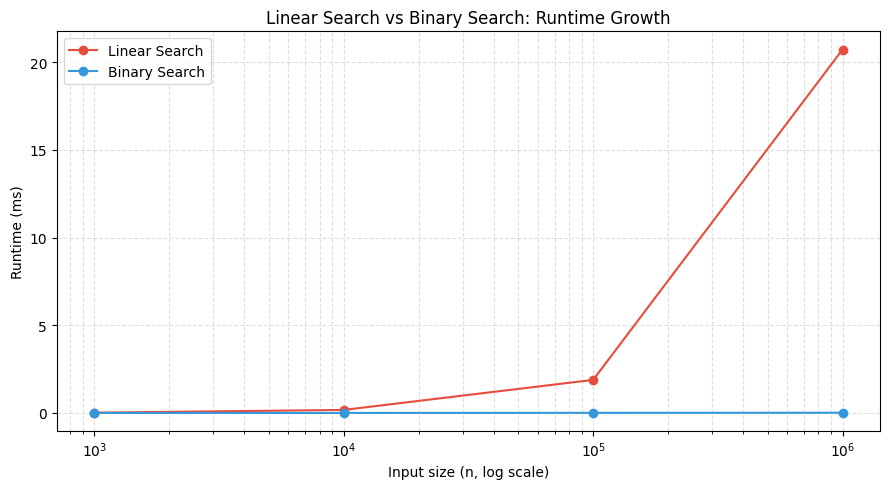

In [7]:
# --- Line chart of runtimes (log scale on x-axis, since sizes grow 10x each time) ---
plt.figure(figsize=(9, 5))
plt.plot(sizes, linear_times, marker='o', label='Linear Search', color='#e74c3c')
plt.plot(sizes, binary_times, marker='o', label='Binary Search', color='#3498db')
plt.xscale('log')
plt.xlabel("Input size (n, log scale)")
plt.ylabel("Runtime (ms)")
plt.title("Linear Search vs Binary Search: Runtime Growth")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Summary Table

| Algorithm      | Best Case | Average Case | Worst Case | Space Complexity      | Requires Sorted Data |
|----------------|-----------|---------------|------------|------------------------|------------------------|
| Linear Search  | O(1)      | O(n)          | O(n)       | O(1)                   | No                     |
| Binary Search  | O(1)      | O(log n)      | O(log n)   | O(1) iterative / O(log n) recursive | Yes  |

**Notes:**
- For small lists, the difference between Linear and Binary Search is negligible — the overhead of sorting first may not be worth it.
- For large, already-sorted (or frequently searched) datasets, Binary Search's `O(log n)` is dramatically faster — as shown in the comparison above.
- If the data isn't sorted and you only need to search once, Linear Search (`O(n)`) is often cheaper overall than sorting (`O(n log n)`) plus Binary Search (`O(log n)`).
